# Week 7 Assignment: Clickbait Headline Classification — Problem, Pipeline, Models, and Analysis
**TECH 405 – Artificial Neural Network & Deep Learning  |  Roshan Marasini**

*Continuation of the Week 6 assignment.* Sections 1–10 reproduce the Week 6 experiments (three models on the same data and split); **Section 11 is new** and analyses *why* the models perform the way they do.

**Problem statement.** Given only the text of a news headline, decide whether it is clickbait (1) or not (0), and find out which kind of neural model reads headlines best.

**Pipeline.** Load data → data-quality checks and EDA → stratified 70/15/15 split → text vectorization (train only) → train 3 models (feed-forward NN, 1D-CNN, LSTM) with early stopping → test-set evaluation (precision, recall, F1, AUC-ROC, confusion matrix) → robustness over seeds → error analysis → **diagnostic experiments (Section 11)**.

**Dataset.** Clickbait Headline Dataset, 32,000 labeled headlines — https://www.kaggle.com/datasets/amananandrai/clickbait-dataset (Chakraborty et al., 2016).


In [1]:
import os, time, random, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)
set_seed(SEED)

DATA_PATH  = "clickbait_data.csv"
MAX_TOKENS = 20000      # vocabulary cap
MAX_LEN    = 25         # from Week 2 length analysis (median 9 words, max 26)
EMB_DIM    = 32         # same embedding size for all models -> fair comparison
EPOCHS     = 15
BATCH      = 64
OUT_DIR    = "outputs6"; os.makedirs(OUT_DIR, exist_ok=True)
print("TensorFlow", tf.__version__)

I0000 00:00:1792198569.832221     141 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792198569.873215     141 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792198571.314043     141 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Dataset: loading, ground truth, and split

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
print("\nLabel distribution (ground truth):")
print(df["clickbait"].value_counts().rename({0: "non-clickbait (0)", 1: "clickbait (1)"}))
df.sample(6, random_state=42)

Shape: (32000, 2)
Missing values: 0 | Duplicate rows: 0

Label distribution (ground truth):
clickbait
non-clickbait (0)    16001
clickbait (1)        15999
Name: count, dtype: int64


,headline,clickbait
23100,Filipino activist arrested for disrupting Mani...,0
17362,"International Board fixes soccer field size, h...",0
8993,24 Rules For Women On A First Date With A Man,1
19566,Political fallout from the sacking of Professo...,0
3798,"Which ""Clueless"" Character Are You Based On Yo...",1
12573,24 Hauntingly Beautiful Tattoos Featuring No F...,1


In [3]:
X, y = df["headline"].astype(str), df["clickbait"]
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
print(f"Train: {len(X_train):,} | Validation: {len(X_val):,} | Test: {len(X_test):,}")
print("Test-set class counts:", y_test.value_counts().to_dict())

Train: 22,400 | Validation: 4,800 | Test: 4,800
Test-set class counts: {0: 2400, 1: 2400}


## 2. Text vectorization (shared by all three models)
The vectorizer is fitted on the **training headlines only**, so no information from validation/test data leaks into the vocabulary. Each headline becomes a fixed-length sequence of 25 integer word indices (index 0 = padding).

In [4]:
vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_mode="int", output_sequence_length=MAX_LEN)
vectorizer.adapt(X_train.values)
def vec(s): return vectorizer(tf.constant(s.values)).numpy()
Xtr, Xva, Xte = vec(X_train), vec(X_val), vec(X_test)
ytr, yva, yte = y_train.values, y_val.values, y_test.values
print("Vocabulary size:", vectorizer.vocabulary_size(), "| Input shape:", Xtr.shape)
print("Example headline :", X_train.iloc[0])
print("Encoded sequence :", Xtr[0])

Vocabulary size: 20000 | Input shape: (22400, 25)
Example headline : 39 Things You'll Only Understand If You Went To College In The Early 2000s
Encoded sequence : [1605   24  139  117  137   54    6  396    2  350    3    4  769 2480
    0    0    0    0    0    0    0    0    0    0    0]


## 3. Model definitions
All three models share the same input (25 tokens) and the same 32-dimensional embedding, so differences in results come from the **architecture**, not the input representation.

* **Model 1: Feed-forward NN** averages all word vectors (ignores word order).
* **Model 2: 1D-CNN** slides 128 filters of width 3 over the sequence to detect local 3-word patterns, then keeps the strongest response of each filter (global max pooling).
* **Model 3: LSTM** reads the headline word by word, carrying a memory state, so it can use word order.

In [5]:
def build_ffnn():
    return keras.Sequential([
        layers.Input(shape=(MAX_LEN,), dtype="int32"),
        layers.Embedding(MAX_TOKENS, EMB_DIM),
        layers.GlobalAveragePooling1D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")], name="FFNN")

def build_cnn():
    return keras.Sequential([
        layers.Input(shape=(MAX_LEN,), dtype="int32"),
        layers.Embedding(MAX_TOKENS, EMB_DIM),
        layers.Conv1D(128, 3, activation="relu"),
        layers.GlobalMaxPooling1D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")], name="CNN_1D")

def build_lstm():
    return keras.Sequential([
        layers.Input(shape=(MAX_LEN,), dtype="int32"),
        layers.Embedding(MAX_TOKENS, EMB_DIM, mask_zero=True),
        layers.LSTM(64),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")], name="LSTM")

# learning rate per model (FFNN: best value found in Week 4; CNN/LSTM: Adam default 0.001)
MODELS = {"FFNN": (build_ffnn, 0.01), "CNN_1D": (build_cnn, 0.001), "LSTM": (build_lstm, 0.001)}

def fit_model(name, seed=SEED, verbose=0):
    builder, lr = MODELS[name]
    set_seed(seed)
    model = builder()
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy", metrics=["accuracy"])
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=BATCH, callbacks=[es], verbose=verbose)
    return model, hist, time.time() - t0

def evaluate(model, X_, y_):
    prob = model.predict(X_, verbose=0).ravel(); pred = (prob >= 0.5).astype(int)
    return dict(accuracy=accuracy_score(y_, pred), precision=precision_score(y_, pred),
                recall=recall_score(y_, pred), f1=f1_score(y_, pred), auc=roc_auc_score(y_, prob)), prob, pred

def curves(hist, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="validation")
    ax[0].set_title(f"{name}: loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="validation")
    ax[1].set_title(f"{name}: accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{name}_curves.png", dpi=150); plt.show()

def report(name, model, hist, secs):
    m, prob, pred = evaluate(model, Xte, yte)
    print(f"=== {name}: TEST SET RESULTS ===")
    for k in ["accuracy", "precision", "recall", "f1", "auc"]:
        print(f"{k:10s}: {m[k]:.4f}")
    print("\n", classification_report(yte, pred, target_names=["Non-clickbait", "Clickbait"], digits=4))
    cm = confusion_matrix(yte, pred)
    fpr, tpr, _ = roc_curve(yte, prob)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ConfusionMatrixDisplay(cm, display_labels=["Non-clickbait", "Clickbait"]).plot(ax=ax[0], cmap="Blues", values_format="d", colorbar=False)
    ax[0].set_title(f"{name}: confusion matrix")
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {m['auc']:.4f}"); ax[1].plot([0, 1], [0, 1], "k--", lw=1)
    ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].set_title(f"{name}: ROC curve"); ax[1].legend(loc="lower right")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{name}_eval.png", dpi=150); plt.show()
    row = dict(model=name, **m, params=model.count_params(), epochs=len(hist.history["loss"]), train_seconds=round(secs, 1), tn=int(cm[0,0]), fp=int(cm[0,1]), fn=int(cm[1,0]), tp=int(cm[1,1]))
    return row, prob, pred, (fpr, tpr)

RESULTS, PROBS, PREDS, ROCS, HISTS, TRAINED = {}, {}, {}, {}, {}, {}
print("Models defined:", list(MODELS))

Models defined: ['FFNN', 'CNN_1D', 'LSTM']


## 4. Model 1 — Feed-forward Neural Network

In [6]:
m = build_ffnn(); m.summary()

Model: "FFNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 25, 32)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 642,177 (2.45 MB)

 Trainable params: 642,177 (2.45 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


350/350 - 3s - 8ms/step - accuracy: 0.9359 - loss: 0.1588 - val_accuracy: 0.9685 - val_loss: 0.0866


Epoch 2/15


350/350 - 2s - 6ms/step - accuracy: 0.9875 - loss: 0.0392 - val_accuracy: 0.9742 - val_loss: 0.0804


Epoch 3/15


...

Epoch 4/15


350/350 - 2s - 7ms/step - accuracy: 0.9869 - loss: 0.0336 - val_accuracy: 0.9260 - val_loss: 0.2602


Epoch 5/15


350/350 - 2s - 5ms/step - accuracy: 0.9912 - loss: 0.0249 - val_accuracy: 0.9585 - val_loss: 0.1873



Trained in 12.5s, 5 epochs


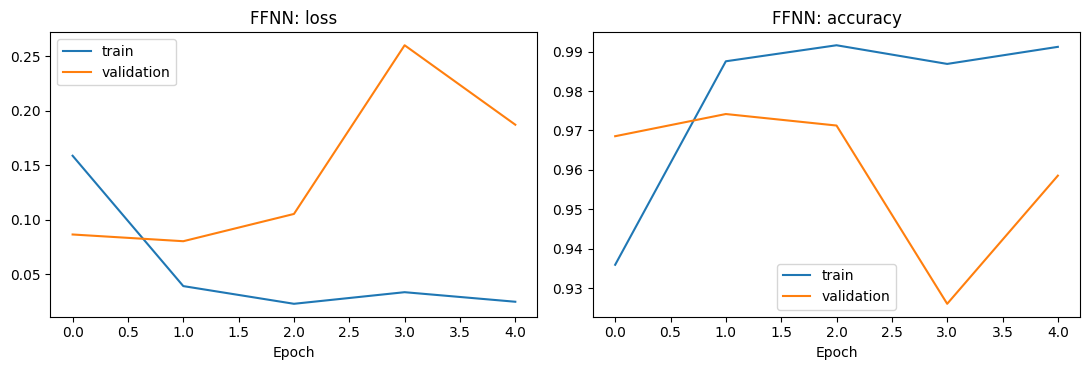

In [7]:
model, hist, secs = fit_model("FFNN", verbose=2)
TRAINED["FFNN"], HISTS["FFNN"] = model, hist
print(f"\nTrained in {secs:.1f}s, {len(hist.history['loss'])} epochs")
curves(hist, "FFNN")

=== FFNN: TEST SET RESULTS ===
accuracy  : 0.9775
precision : 0.9787
recall    : 0.9762
f1        : 0.9775
auc       : 0.9974

                precision    recall  f1-score   support

Non-clickbait     0.9763    0.9788    0.9775      2400
    Clickbait     0.9787    0.9762    0.9775      2400

     accuracy                         0.9775      4800
    macro avg     0.9775    0.9775    0.9775      4800
 weighted avg     0.9775    0.9775    0.9775      4800



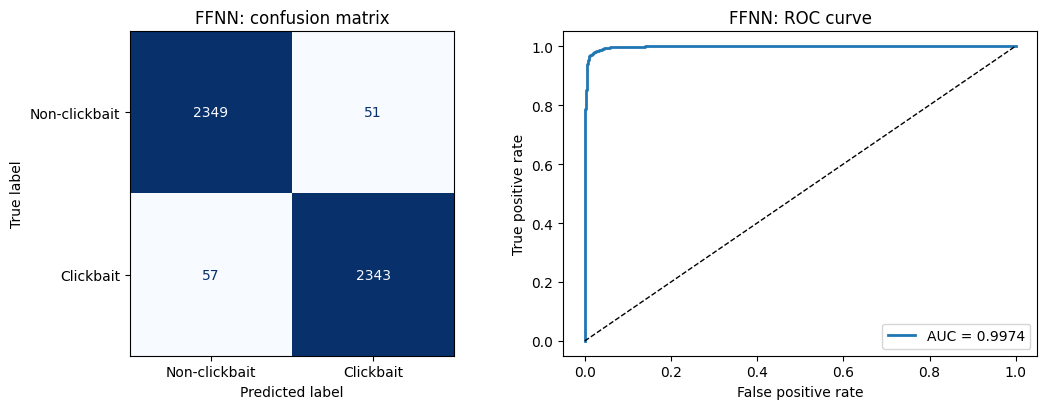

In [8]:
RESULTS["FFNN"], PROBS["FFNN"], PREDS["FFNN"], ROCS["FFNN"] = report("FFNN", model, hist, secs)

## 5. Model 2 — 1D Convolutional Neural Network (CNN)

In [9]:
m = build_cnn(); m.summary()

Model: "CNN_1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 25, 32)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 23, 128)        │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 660,737 (2.52 MB)

 Trainable params: 660,737 (2.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


350/350 - 4s - 11ms/step - accuracy: 0.9127 - loss: 0.2044 - val_accuracy: 0.9627 - val_loss: 0.1046


Epoch 2/15


350/350 - 5s - 15ms/step - accuracy: 0.9880 - loss: 0.0377 - val_accuracy: 0.9729 - val_loss: 0.0873


Epoch 3/15


...

Epoch 4/15


350/350 - 5s - 15ms/step - accuracy: 0.9997 - loss: 0.0019 - val_accuracy: 0.9702 - val_loss: 0.1230


Epoch 5/15


350/350 - 5s - 13ms/step - accuracy: 0.9999 - loss: 5.5049e-04 - val_accuracy: 0.9715 - val_loss: 0.1355



Trained in 26.5s, 5 epochs


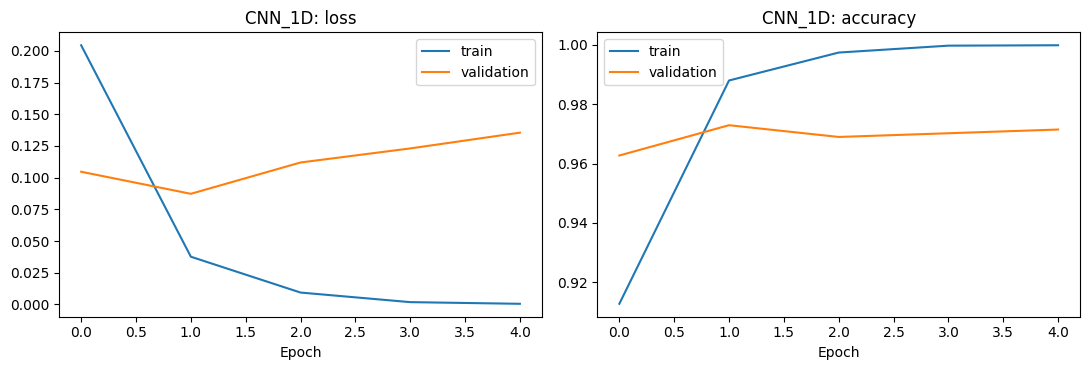

In [10]:
model, hist, secs = fit_model("CNN_1D", verbose=2)
TRAINED["CNN_1D"], HISTS["CNN_1D"] = model, hist
print(f"\nTrained in {secs:.1f}s, {len(hist.history['loss'])} epochs")
curves(hist, "CNN_1D")

=== CNN_1D: TEST SET RESULTS ===
accuracy  : 0.9777
precision : 0.9795
recall    : 0.9758
f1        : 0.9777
auc       : 0.9967

                precision    recall  f1-score   support

Non-clickbait     0.9759    0.9796    0.9778      2400
    Clickbait     0.9795    0.9758    0.9777      2400

     accuracy                         0.9777      4800
    macro avg     0.9777    0.9777    0.9777      4800
 weighted avg     0.9777    0.9777    0.9777      4800



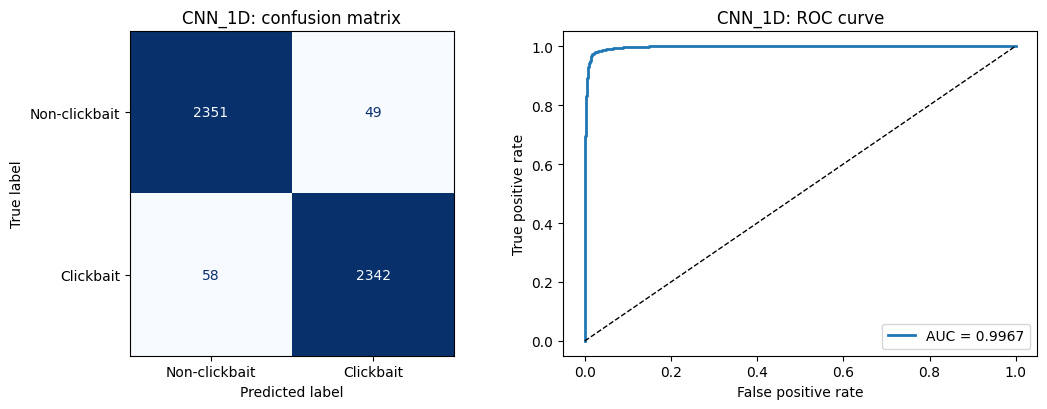

In [11]:
RESULTS["CNN_1D"], PROBS["CNN_1D"], PREDS["CNN_1D"], ROCS["CNN_1D"] = report("CNN_1D", model, hist, secs)

## 6. Model 3 — Long Short-Term Memory (LSTM)

In [12]:
m = build_lstm(); m.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 25, 32)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 664,897 (2.54 MB)

 Trainable params: 664,897 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


E0000 00:00:1792198686.328943     141 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


350/350 - 8s - 22ms/step - accuracy: 0.9267 - loss: 0.1696 - val_accuracy: 0.9721 - val_loss: 0.0818


Epoch 2/15


350/350 - 10s - 29ms/step - accuracy: 0.9900 - loss: 0.0316 - val_accuracy: 0.9744 - val_loss: 0.0892


Epoch 3/15


350/350 - 11s - 31ms/step - accuracy: 0.9970 - loss: 0.0110 - val_accuracy: 0.9733 - val_loss: 0.0952


Epoch 4/15


350/350 - 10s - 29ms/step - accuracy: 0.9988 - loss: 0.0050 - val_accuracy: 0.9731 - val_loss: 0.1002



Trained in 42.5s, 4 epochs


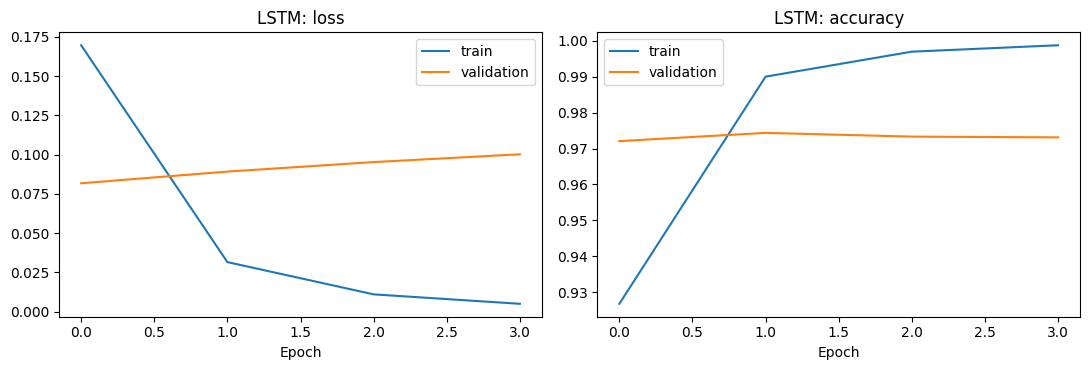

In [13]:
model, hist, secs = fit_model("LSTM", verbose=2)
TRAINED["LSTM"], HISTS["LSTM"] = model, hist
print(f"\nTrained in {secs:.1f}s, {len(hist.history['loss'])} epochs")
curves(hist, "LSTM")

=== LSTM: TEST SET RESULTS ===
accuracy  : 0.9717
precision : 0.9813
recall    : 0.9617
f1        : 0.9714
auc       : 0.9961

                precision    recall  f1-score   support

Non-clickbait     0.9624    0.9817    0.9719      2400
    Clickbait     0.9813    0.9617    0.9714      2400

     accuracy                         0.9717      4800
    macro avg     0.9719    0.9717    0.9717      4800
 weighted avg     0.9719    0.9717    0.9717      4800



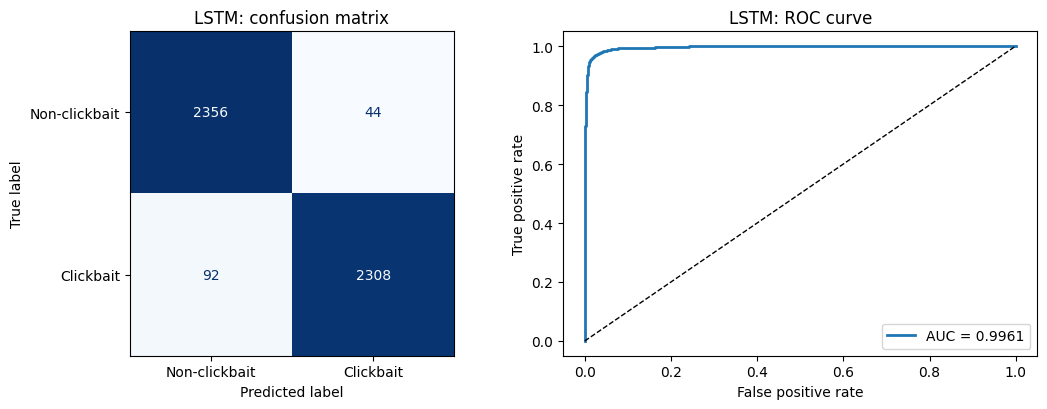

In [14]:
RESULTS["LSTM"], PROBS["LSTM"], PREDS["LSTM"], ROCS["LSTM"] = report("LSTM", model, hist, secs)

## 7. Model comparison (test set)

In [15]:
cmp_df = pd.DataFrame(RESULTS.values()).set_index("model")
cmp_df = cmp_df[["accuracy", "precision", "recall", "f1", "auc", "params", "epochs", "train_seconds"]]
cmp_df.to_csv(f"{OUT_DIR}/model_comparison.csv")
cmp_df.round(4)

,accuracy,precision,recall,f1,auc,params,epochs,train_seconds
model,,,,,,,,
FFNN,0.9775,0.9787,0.9762,0.9775,0.9974,642177,5,12.5
CNN_1D,0.9777,0.9795,0.9758,0.9777,0.9967,660737,5,26.5
LSTM,0.9717,0.9813,0.9617,0.9714,0.9961,664897,4,42.5


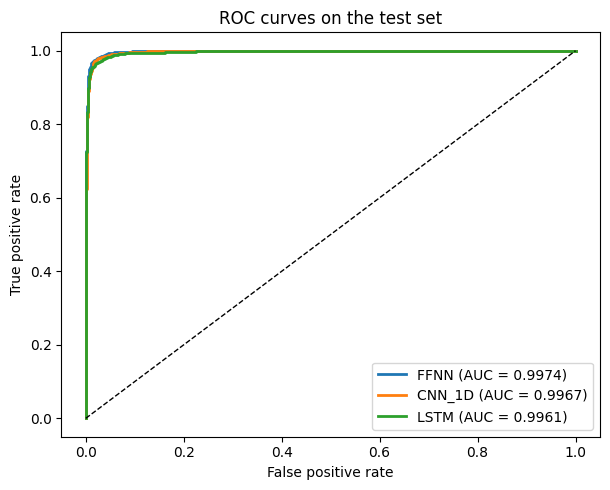

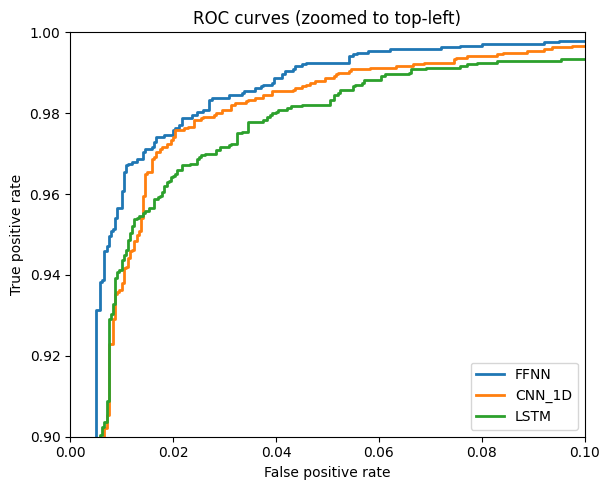

In [16]:
colors = {"FFNN": "tab:blue", "CNN_1D": "tab:orange", "LSTM": "tab:green"}
plt.figure(figsize=(6.2, 5))
for n in MODELS:
    fpr, tpr = ROCS[n]
    plt.plot(fpr, tpr, lw=2, color=colors[n], label=f"{n} (AUC = {RESULTS[n]['auc']:.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves on the test set")
plt.legend(loc="lower right"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/roc_overlay.png", dpi=150); plt.show()

# zoomed view of the top-left corner, where the curves differ
plt.figure(figsize=(6.2, 5))
for n in MODELS:
    fpr, tpr = ROCS[n]; plt.plot(fpr, tpr, lw=2, color=colors[n], label=n)
plt.xlim(0, 0.1); plt.ylim(0.9, 1.0); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (zoomed to top-left)"); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/roc_zoom.png", dpi=150); plt.show()

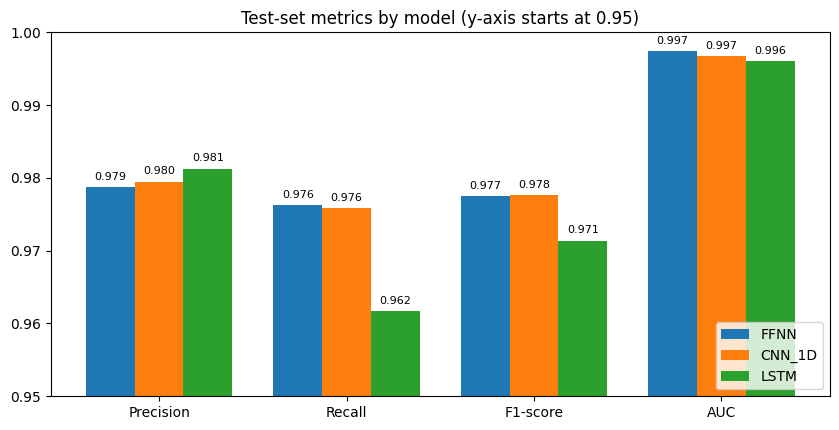

In [17]:
metrics = ["precision", "recall", "f1", "auc"]
x = np.arange(len(metrics)); w = 0.26
plt.figure(figsize=(8.5, 4.4))
for i, n in enumerate(MODELS):
    vals = [RESULTS[n][k] for k in metrics]
    bars = plt.bar(x + (i - 1) * w, vals, w, label=n, color=colors[n])
    for b, v in zip(bars, vals): plt.text(b.get_x() + b.get_width() / 2, v + 0.001, f"{v:.3f}", ha="center", fontsize=8)
plt.xticks(x, ["Precision", "Recall", "F1-score", "AUC"]); plt.ylim(0.95, 1.0)
plt.title("Test-set metrics by model (y-axis starts at 0.95)"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/metric_bars.png", dpi=150); plt.show()

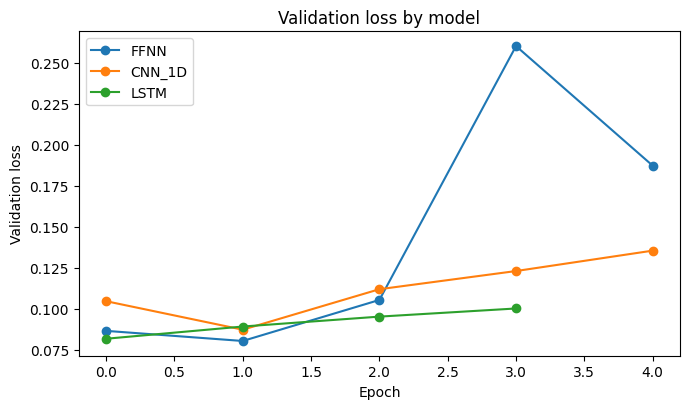

In [18]:
plt.figure(figsize=(7, 4.2))
for n in MODELS:
    plt.plot(HISTS[n].history["val_loss"], marker="o", color=colors[n], label=n)
plt.xlabel("Epoch"); plt.ylabel("Validation loss"); plt.title("Validation loss by model"); plt.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/val_loss_overlay.png", dpi=150); plt.show()

## 8. Robustness: repeating training with different random seeds
A single run can be lucky or unlucky, so each model is trained with three seeds (42, 7, 123). Mean ± standard deviation of the **test** metrics shows whether the differences between models are larger than run-to-run noise. (Seed 42 reuses the run above.)

In [19]:
seed_rows = []
for n in MODELS:
    seed_rows.append(dict(model=n, seed=42, **{k: RESULTS[n][k] for k in ["precision", "recall", "f1", "auc"]}))
    for s in [7, 123]:
        mdl, h, _ = fit_model(n, seed=s)
        r, _, _ = evaluate(mdl, Xte, yte)
        seed_rows.append(dict(model=n, seed=s, **{k: r[k] for k in ["precision", "recall", "f1", "auc"]}))
        print(f"{n:7s} seed={s:<4d} F1={r['f1']:.4f} AUC={r['auc']:.4f}")
seed_df = pd.DataFrame(seed_rows); seed_df.to_csv(f"{OUT_DIR}/seed_runs.csv", index=False)

FFNN    seed=7    F1=0.9769 AUC=0.9973


FFNN    seed=123  F1=0.9755 AUC=0.9975


CNN_1D  seed=7    F1=0.9746 AUC=0.9958


CNN_1D  seed=123  F1=0.9715 AUC=0.9961


LSTM    seed=7    F1=0.9742 AUC=0.9971


LSTM    seed=123  F1=0.9746 AUC=0.9965


In [20]:
summ = seed_df.groupby("model")[["precision", "recall", "f1", "auc"]].agg(["mean", "std"]).round(4)
summ = summ.loc[list(MODELS)]
summ.to_csv(f"{OUT_DIR}/seed_summary.csv")
summ

precision          recall              f1             auc        
            mean     std    mean     std    mean     std    mean     std
model                                                                   
FFNN      0.9810  0.0062  0.9724  0.0078  0.9766  0.0010  0.9974  0.0001
CNN_1D    0.9770  0.0032  0.9722  0.0063  0.9746  0.0031  0.9962  0.0005
LSTM      0.9811  0.0002  0.9658  0.0036  0.9734  0.0018  0.9965  0.0005

## 9. Error analysis

In [21]:
test_df = pd.DataFrame({"headline": X_test.values, "true": yte})
for n in MODELS:
    test_df[n] = PREDS[n]; test_df[n + "_p"] = PROBS[n].round(3)
wrong = {n: (test_df[n] != test_df["true"]) for n in MODELS}
all_wrong  = test_df[wrong["FFNN"] & wrong["CNN_1D"] & wrong["LSTM"]]
any_wrong  = test_df[wrong["FFNN"] | wrong["CNN_1D"] | wrong["LSTM"]]
print("Misclassified by FFNN  :", int(wrong["FFNN"].sum()))
print("Misclassified by CNN_1D:", int(wrong["CNN_1D"].sum()))
print("Misclassified by LSTM  :", int(wrong["LSTM"].sum()))
print("Misclassified by ALL three:", len(all_wrong), "| by at least one:", len(any_wrong))
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)
print("\nHeadlines ALL three models get wrong (true label 1 = clickbait):")
all_wrong[["headline", "true", "FFNN_p", "CNN_1D_p", "LSTM_p"]].head(8)

Misclassified by FFNN  : 108
Misclassified by CNN_1D: 107
Misclassified by LSTM  : 136
Misclassified by ALL three: 52 | by at least one: 203

Headlines ALL three models get wrong (true label 1 = clickbait):


,headline,true,FFNN_p,CNN_1D_p,LSTM_p
45,Snuffleupagus Without Fur Is A Goddamned Nightmare,1,0.404,0.459,0.057
133,Adorable Red Panda Cubs Make Public Debut At Chicago Zoo,1,0.001,0.038,0.089
272,A Good Time to Remember Investment Fundamentals,0,0.572,0.736,0.538
320,Happy Gilmore Was On to Something,0,0.921,0.993,0.881
334,Pop starlet Kylie Minogue has early-stage breast cancer,0,0.887,0.991,0.523
497,Making the Sims Into Neighbors You Can Relate To,0,0.996,0.999,0.989
558,Top-Ranked Olympic Skier Gus Kenworthy Comes Out As Gay With ESPN Cover,1,0.009,0.232,0.009
647,Drowning Wombat Saved From Lake By Fishermen Who Caught Him In A Net,1,0.155,0.264,0.013


## 10. Live sample check on new headlines

In [22]:
def predict_all(text):
    seq = vectorizer(tf.constant([text])).numpy()
    return {n: float(TRAINED[n].predict(seq, verbose=0)[0, 0]) for n in MODELS}

samples = [
    "You Won't Believe What This Dog Did When Left Home Alone",
    "Senate Passes Infrastructure Bill After Months Of Negotiation",
    "24 Signs You Grew Up In The 2000s",
    "Central Bank Raises Interest Rates By Half A Point",
    "This One Trick Will Change The Way You Think About Coffee Forever",
    "Scientists Discover New Species Of Frog In Amazon Rainforest",
]
rows = []
for h in samples:
    p = predict_all(h)
    rows.append({"headline": h, **{f"{n} P(clickbait)": round(v, 3) for n, v in p.items()}})
pd.DataFrame(rows)

,headline,FFNN P(clickbait),CNN_1D P(clickbait),LSTM P(clickbait)
0,You Won't Believe What This Dog Did When Left Home Alone,1.0,0.999,0.999
1,Senate Passes Infrastructure Bill After Months Of Negotiation,0.0,0.000,0.001
2,24 Signs You Grew Up In The 2000s,1.0,1.000,0.997
3,Central Bank Raises Interest Rates By Half A Point,0.0,0.000,0.001
4,This One Trick Will Change The Way You Think About Coffee Forever,1.0,1.000,0.999
5,Scientists Discover New Species Of Frog In Amazon Rainforest,0.0,0.002,0.017


## 11. Analysis: why do the models perform the way they do?
Sections 7–9 show *what* the models score. The diagnostic experiments below test *why*, using the models trained above (seed 42). All numbers use the held-out **test** set unless stated otherwise.

### 11.1 Overfitting profile (from the training histories)

In [23]:
rows = []
for n in MODELS:
    h = HISTS[n].history; b = int(np.argmin(h["val_loss"]))
    rows.append(dict(model=n, best_epoch=b + 1, epochs_run=len(h["loss"]),
                     train_acc_best=h["accuracy"][b], val_acc_best=h["val_accuracy"][b],
                     train_acc_last=h["accuracy"][-1], val_acc_last=h["val_accuracy"][-1],
                     val_loss_best=h["val_loss"][b], val_loss_last=h["val_loss"][-1]))
over_df = pd.DataFrame(rows).set_index("model")
over_df["gap_last"] = over_df["train_acc_last"] - over_df["val_acc_last"]
over_df.to_csv(f"{OUT_DIR}/overfitting_profile.csv")
over_df.round(4)

,best_epoch,epochs_run,train_acc_best,val_acc_best,train_acc_last,val_acc_last,val_loss_best,val_loss_last,gap_last
model,,,,,,,,,
FFNN,2,5,0.9875,0.9742,0.9912,0.9585,0.0804,0.1873,0.0327
CNN_1D,2,5,0.9880,0.9729,0.9999,0.9715,0.0873,0.1355,0.0284
LSTM,1,4,0.9267,0.9721,0.9988,0.9731,0.0818,0.1002,0.0257


### 11.2 Does word order matter? (word-shuffle test)
If a model really uses word **order**, scrambling the words of every *test* headline should hurt it. A model that only uses **which words appear** should be unaffected. Each test headline is shuffled 5 times with different seeds and the metrics are averaged. The trained models are not changed.

In [24]:
def shuffle_words(text, rng):
    w = text.split(); rng.shuffle(w); return " ".join(w)

def probs_for(model, texts):
    seq = vectorizer(tf.constant(list(texts))).numpy()
    return model.predict(seq, verbose=0).ravel()

order_rows = []
for n in MODELS:
    f1s, aucs = [], []
    for s in range(5):
        rng = random.Random(100 + s)
        shuf = [shuffle_words(t, rng) for t in X_test.values]
        p = probs_for(TRAINED[n], shuf); pr = (p >= 0.5).astype(int)
        f1s.append(f1_score(yte, pr)); aucs.append(roc_auc_score(yte, p))
    order_rows.append(dict(model=n, f1_original=RESULTS[n]["f1"], f1_shuffled=float(np.mean(f1s)),
                           f1_drop=RESULTS[n]["f1"] - float(np.mean(f1s)),
                           auc_original=RESULTS[n]["auc"], auc_shuffled=float(np.mean(aucs)),
                           auc_drop=RESULTS[n]["auc"] - float(np.mean(aucs))))
order_df = pd.DataFrame(order_rows).set_index("model")
order_df.to_csv(f"{OUT_DIR}/word_order_test.csv")
order_df.round(4)

,f1_original,f1_shuffled,f1_drop,auc_original,auc_shuffled,auc_drop
model,,,,,,
FFNN,0.9775,0.9775,0.0000,0.9974,0.9974,0.0000
CNN_1D,0.9777,0.9730,0.0046,0.9967,0.9960,0.0007
LSTM,0.9714,0.9590,0.0124,0.9961,0.9943,0.0018


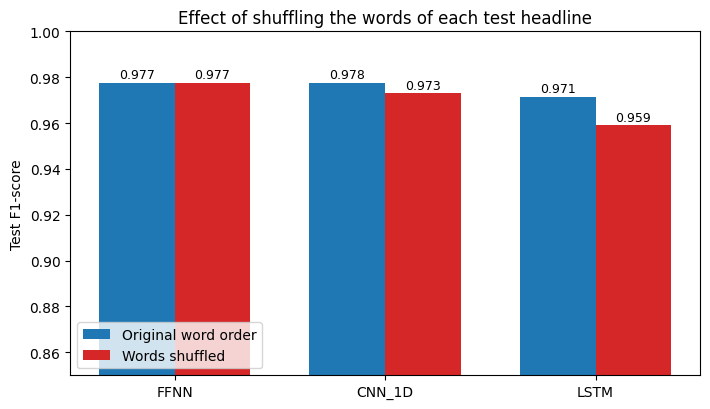

In [25]:
plt.figure(figsize=(7.2, 4.2))
x = np.arange(len(MODELS)); w = 0.36
b1 = plt.bar(x - w/2, order_df["f1_original"], w, label="Original word order", color="tab:blue")
b2 = plt.bar(x + w/2, order_df["f1_shuffled"], w, label="Words shuffled", color="tab:red")
for b in list(b1) + list(b2):
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 0.002, f"{b.get_height():.3f}", ha="center", fontsize=9)
plt.xticks(x, list(MODELS)); plt.ylim(0.85, 1.0); plt.ylabel("Test F1-score")
plt.title("Effect of shuffling the words of each test headline"); plt.legend(loc="lower left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/word_shuffle.png", dpi=150); plt.show()

### 11.3 Which words carry the signal? (log-odds of words in the training set)
For every word that appears in at least 50 training headlines, the smoothed log-odds ratio compares how often it appears in clickbait vs. non-clickbait headlines. A large positive value means the word is a strong clickbait cue; a large negative value means a strong news cue.

In [26]:
import re
from collections import Counter
tok = lambda s: re.findall(r"[a-z0-9']+", s.lower())
cnt = {0: Counter(), 1: Counter()}
for t, l in zip(X_train.values, ytr): cnt[int(l)].update(set(tok(t)))   # document frequency
n0, n1 = int((ytr == 0).sum()), int((ytr == 1).sum())
vocab_w = [w for w in set(cnt[0]) | set(cnt[1]) if cnt[0][w] + cnt[1][w] >= 50]
lo = {w: np.log((cnt[1][w] + 1) / (n1 + 2)) - np.log((cnt[0][w] + 1) / (n0 + 2)) for w in vocab_w}
top_cb  = sorted(lo.items(), key=lambda kv: -kv[1])[:12]
top_nws = sorted(lo.items(), key=lambda kv:  kv[1])[:12]
pd.set_option("display.width", 200)
print("Strongest CLICKBAIT cues (log-odds, #clickbait headlines containing it, #non-clickbait):")
print(pd.DataFrame([(w, round(v, 2), cnt[1][w], cnt[0][w]) for w, v in top_cb], columns=["word", "log-odds", "clickbait", "non-clickbait"]).to_string(index=False))
print("\nStrongest NON-CLICKBAIT (news) cues:")
print(pd.DataFrame([(w, round(v, 2), cnt[1][w], cnt[0][w]) for w, v in top_nws], columns=["word", "log-odds", "clickbait", "non-clickbait"]).to_string(index=False))

Strongest CLICKBAIT cues (log-odds, #clickbait headlines containing it, #non-clickbait):
    word  log-odds  clickbait  non-clickbait
    2015      5.86        351              0
  here's      5.69        295              0
   these      5.42        451              1
   every      5.41        223              0
  zodiac      5.36        212              0
  you're      5.34        208              0
actually      5.33        412              1
  tweets      5.29        198              0
     you      5.26       3268             16
  things      5.18        711              3
   guess      5.18        177              0
  you'll      5.10        163              0

Strongest NON-CLICKBAIT (news) cues:
       word  log-odds  clickbait  non-clickbait
      kills     -5.26          0            192
       iraq     -5.02          0            150
     leader     -4.60          0             99
       wins     -4.57          1            193
   wikinews     -4.42          0             82


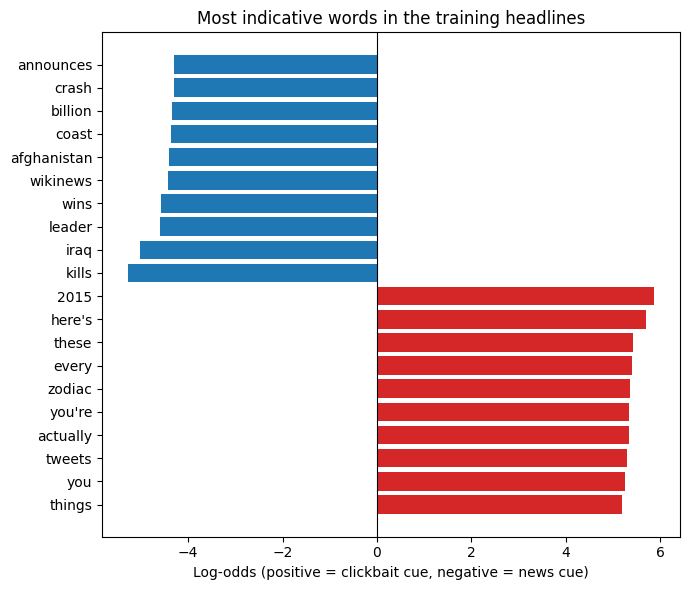

In [27]:
sel = top_cb[:10][::-1] + top_nws[:10]
plt.figure(figsize=(7, 6))
plt.barh([w for w, _ in sel], [v for _, v in sel], color=["tab:red" if v > 0 else "tab:blue" for _, v in sel])
plt.axvline(0, color="k", lw=0.8); plt.xlabel("Log-odds (positive = clickbait cue, negative = news cue)")
plt.title("Most indicative words in the training headlines"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/indicative_words.png", dpi=150); plt.show()

### 11.4 Performance by headline length (test accuracy)

In [28]:
wl = X_test.str.split().str.len().values
labels = ["<=6", "7-8", "9-10", "11-12", "13+"]
bucket = np.asarray(pd.cut(wl, bins=[0, 6, 8, 10, 12, 100], labels=labels))
len_rows = []
for lab in labels:
    m = bucket == lab
    r = {"words": lab, "n": int(m.sum()), "clickbait_share": round(float(yte[m].mean()), 3)}
    for n in MODELS: r[n] = accuracy_score(yte[m], PREDS[n][m])
    len_rows.append(r)
len_df = pd.DataFrame(len_rows).set_index("words"); len_df.to_csv(f"{OUT_DIR}/accuracy_by_length.csv")
len_df.round(4)

,n,clickbait_share,FFNN,CNN_1D,LSTM
words,,,,,
<=6,800,0.314,0.9688,0.9662,0.9712
7-8,1395,0.333,0.9828,0.9778,0.9806
9-10,1349,0.571,0.9770,0.9800,0.9696
11-12,827,0.696,0.9770,0.9831,0.9637
13+,429,0.788,0.9790,0.9814,0.9650


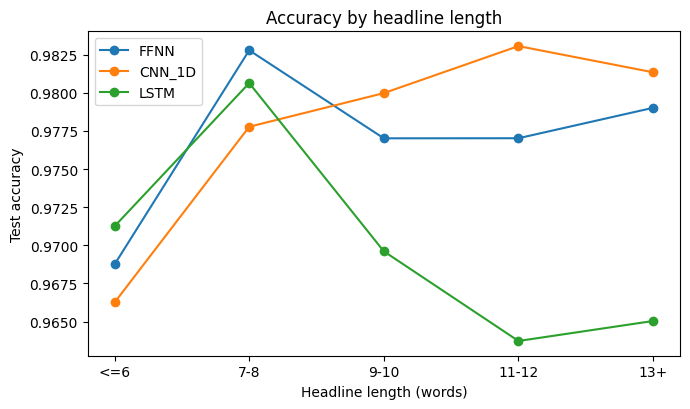

In [29]:
plt.figure(figsize=(7, 4.2))
for n in MODELS: plt.plot(labels, len_df[n], marker="o", color=colors[n], label=n)
plt.ylabel("Test accuracy"); plt.xlabel("Headline length (words)"); plt.title("Accuracy by headline length")
plt.legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/accuracy_by_length.png", dpi=150); plt.show()

### 11.5 Reference baseline: TF-IDF + logistic regression
To test the idea that this task is mostly about **which words appear**, a classical model that sees only word and word-pair counts (no embeddings, no word order beyond 2-word pairs) is trained as a *diagnostic reference*. It is not one of the three compared neural models and was not tuned (C = 4).

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr_t = tfidf.fit_transform(X_train); Xte_t = tfidf.transform(X_test)
logreg = LogisticRegression(max_iter=1000, C=4.0, random_state=SEED).fit(Xtr_t, ytr)
p_lr = logreg.predict_proba(Xte_t)[:, 1]; pr_lr = (p_lr >= 0.5).astype(int)
RESULTS["TFIDF_LogReg"] = dict(model="TFIDF_LogReg", accuracy=accuracy_score(yte, pr_lr), precision=precision_score(yte, pr_lr),
                              recall=recall_score(yte, pr_lr), f1=f1_score(yte, pr_lr), auc=roc_auc_score(yte, p_lr))
final_df = pd.DataFrame(RESULTS.values()).set_index("model")[["accuracy", "precision", "recall", "f1", "auc"]]
final_df.to_csv(f"{OUT_DIR}/final_comparison_with_baseline.csv")
final_df.round(4)

,accuracy,precision,recall,f1,auc
model,,,,,
FFNN,0.9775,0.9787,0.9762,0.9775,0.9974
CNN_1D,0.9777,0.9795,0.9758,0.9777,0.9967
LSTM,0.9717,0.9813,0.9617,0.9714,0.9961
TFIDF_LogReg,0.9752,0.9762,0.9742,0.9752,0.9966


## 12. Conclusions
**Test-set results (seed 42)**

| Model | Precision | Recall | F1 | AUC |
|---|---|---|---|---|
| Feed-forward NN | 0.9787 | 0.9762 | 0.9775 | 0.9974 |
| 1D-CNN | 0.9795 | 0.9758 | 0.9777 | 0.9967 |
| LSTM | 0.9813 | 0.9617 | 0.9714 | 0.9961 |
| *Reference: TF-IDF + logistic regression* | 0.9762 | 0.9742 | 0.9752 | 0.9966 |

**Why do the models perform the way they do?**
* **All models overfit within 1–2 epochs** (best epoch 2, 2, and 1; training accuracy up to ~100% while validation loss rises), so more capacity brings no benefit and early stopping is essential.
* **Word order adds little.** Shuffling the words of every test headline leaves the feed-forward model unchanged (F1 0.9775) and lowers the CNN's F1 by only 0.005 and the LSTM's by 0.012 (still above 0.959).
* **Which words appear is what matters.** Strong clickbait cues are second-person and teaser words ("you", "these", "here's", "actually"). But strong cues also include artifacts — "2015" (351 clickbait vs. 0 non-clickbait headlines) and "wikinews" (82 non-clickbait vs. 0) — plus news-topic words ("kills", "iraq", "afghanistan"). Part of the accuracy therefore reflects source/topic style rather than clickbait itself.
* **The LSTM is weaker on long, mostly clickbait headlines** (accuracy 0.964–0.965 for 11+ words vs. 0.977–0.983 for the other models), which explains its lower recall.
* **A classical TF-IDF + logistic-regression model is almost as good** (F1 0.9752), so the neural models add only about 0.002–0.003 F1 on this dataset.
* 52 of 4,800 test headlines (1.1%) are misclassified by all three models — typically ambiguous or noisily labeled headlines.

**Answer:** for short, keyword-driven headlines, a simple feed-forward network is as good as or better than the CNN and LSTM, and the very high scores partly reflect dataset artifacts, so they probably overstate performance on clickbait from other publishers.
